# MaizeCare: maize leaf disease and severity

**Nothing is trained in this notebook.** The models were trained earlier with the project's scripts and saved to
Google Drive. Here they are loaded from Drive and run with the same code as the scripts and the web app.

1. Data
2. Exploratory data analysis
3. Stage 1: the classifier (which disease?)
4. The leaf mask
5. Stage 2: the autoencoder (how severe?)
6. Test results against the targets
7. The full pipeline on test photos

Run it in Google Colab (a CPU runtime is enough): Runtime -> Run all.

In [1]:
from google.colab import drive

drive.mount("/content/drive")
!pip install -q "maize[data,serve] @ git+https://github.com/Kos-en/maizecare.git@main"

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os

os.environ["KERAS_BACKEND"] = "torch"  # the backend the models were trained with

import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, roc_curve

from maize.autoencoder import Autoencoder, compare
from maize.classifier import build
from maize.pipeline import HEALTHY, load_manifest, near_pairs, select
from maize.preprocess import AE_SIZE, CLS_SIZE, error_map, mask_background, prepare, resize
from maize.serve import Scorer, onnx_runner

COLOURS = {"Healthy": "#1baf7a", "MLB": "#2a78d6", "MLND": "#eda100", "MSV": "#e34948"}  # one colour per class
MARKERS = {"Healthy": "o", "MLB": "s", "MLND": "^", "MSV": "D"}                         # and a shape, for scatters

### The trained models, from Drive

| Folder on Drive | What is in it |
|---|---|
| `maize_models/clf_mobilenet_v2/` | the chosen classifier: `classifier.onnx`, `classifier.json` (labels and test scores), `history.csv` |
| `maize_models/clf_*/` | the other three backbones, for the comparison |
| `maize_models/v2/ae_*/` | the two autoencoders: `autoencoder.keras`, `model.onnx`, `history.csv`, `validation.json` |
| the evaluated `ae_*` folder | the output of `maize-evaluate`: `calibration.json`, `metrics.json`, `test_scores.csv`, figures |

In [3]:
ROOT = Path("/content/drive/MyDrive")      # the photos, manifest.csv and the image caches
MODELS = ROOT / "maize_models"
CLASSIFIER = MODELS / "clf_mobilenet_v2"   # the chosen classifier
RUN = MODELS / "v2"                        # the autoencoders
AE = next(f for f in sorted(RUN.glob("ae_*")) if (f / "metrics.json").exists())  # the one maize-evaluate scored

classifier_info = json.loads((CLASSIFIER / "classifier.json").read_text())
calibration = json.loads((AE / "calibration.json").read_text())
metrics = json.loads((AE / "metrics.json").read_text())
LABELS = classifier_info["labels"]
print("classifier:", CLASSIFIER.name, "| autoencoder:", AE.name)


def read_photo(path):
    """One photo from Drive, as RGB."""
    return cv2.cvtColor(cv2.imread(str(ROOT / path)), cv2.COLOR_BGR2RGB)

classifier: clf_mobilenet_v2 | autoencoder: ae_conv


## 1. Data

The data pipeline (`maize-prepare`) checks every photo and groups near copies: the same leaf photographed twice,
close on both pHash and aHash. It drops groups holding two classes and splits **whole groups** 70 / 15 / 15, so
the same leaf can never be in both training and test.

In [4]:
df = load_manifest(ROOT)
usable = select(df)
display(df.groupby(["label", "status"]).size().unstack(fill_value=0))
display(usable.groupby(["label", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]])

status,duplicate_exact,label_conflict,ok
label,,,
Healthy,1152,13,8690
MLB,0,0,5276
MLND,966,3,9376
MSV,2005,15,8100


split,train,val,test
label,,,
Healthy,6083,1303,1304
MLB,3693,791,792
MLND,6563,1406,1407
MSV,5670,1215,1215


**Leak check:** find every near-copy pair again and count the pairs that sit in two different splits.

In [5]:
pairs = near_pairs(usable)
split = usable["split"].to_numpy()
print("near-copy pairs across splits:", (split[pairs[:, 0]] != split[pairs[:, 1]]).sum(), "(must be 0)")

near-copy pairs across splits: 0 (must be 0)


## 2. Exploratory data analysis

On a random sample of photos per class: class balance, photo size, colour, brightness and a t-SNE map. The
question behind each one: could a model tell the classes apart for the wrong reason (photo size, lighting)
instead of the disease?

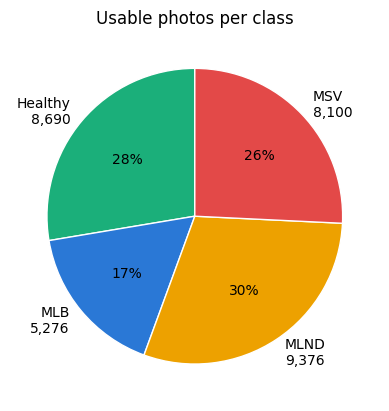

In [6]:
counts = usable["label"].value_counts().reindex(LABELS)
plt.pie(counts, labels=[f"{c}\n{n:,}" for c, n in counts.items()], colors=[COLOURS[c] for c in LABELS],
        autopct="%1.0f%%", startangle=90, wedgeprops={"edgecolor": "white"})
plt.title("Usable photos per class")
plt.show()

In [7]:
SAMPLE = 150  # photos per class


def describe_photo(path):
    rgb = read_photo(path)
    return {"width": rgb.shape[1], "height": rgb.shape[0], "brightness": rgb.mean(),
            "colour_hist": [np.histogram(rgb[..., c], bins=64, range=(0, 256), density=True)[0] for c in range(3)],
            "pixels": cv2.resize(rgb, (64, 64)).ravel() / 255}


sample = usable.sample(frac=1, random_state=0).groupby("label").head(SAMPLE)
with ThreadPoolExecutor(16) as pool:  # reading from Drive is much faster in parallel
    eda = pd.DataFrame(list(pool.map(describe_photo, sample["path"])), index=sample.index).join(sample["label"])

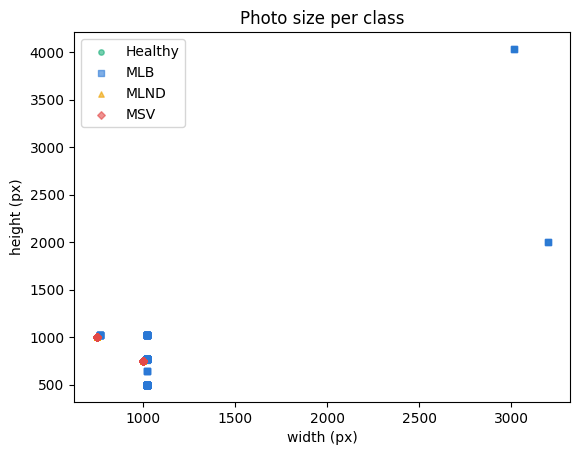

In [8]:
for label, part in eda.groupby("label"):
    plt.scatter(part["width"], part["height"], s=15, alpha=0.6, color=COLOURS[label], marker=MARKERS[label],
                label=label)
plt.xlabel("width (px)")
plt.ylabel("height (px)")
plt.title("Photo size per class")
plt.legend()
plt.show()

Every photo is resized to the same square before it reaches a model, so photo size itself cannot give a class
away.

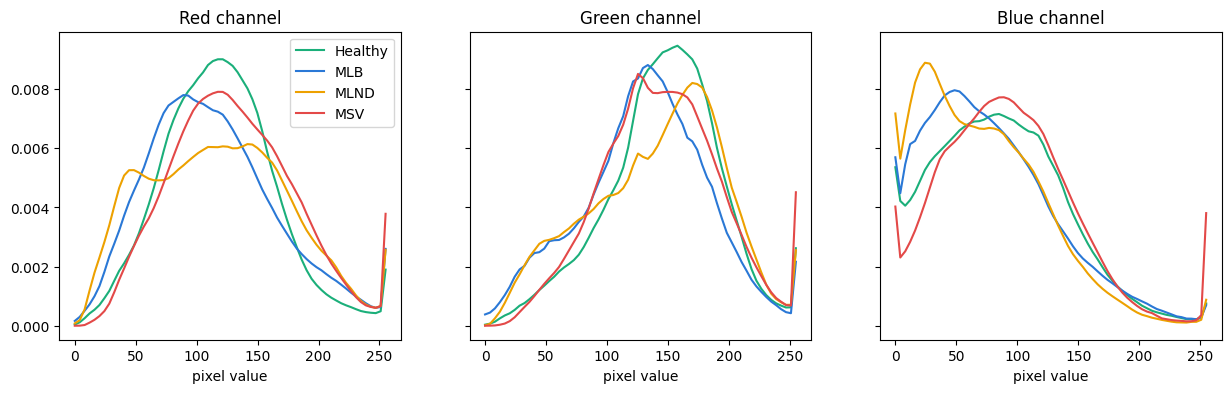

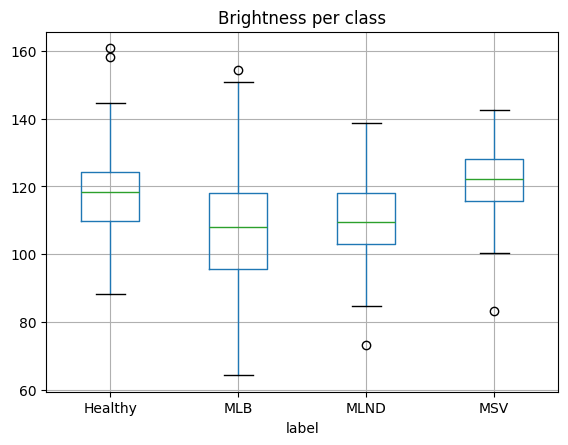

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for c, (ax, name) in enumerate(zip(axes, ["Red", "Green", "Blue"])):
    for label, part in eda.groupby("label"):
        ax.plot(np.linspace(0, 255, 64), np.mean([h[c] for h in part["colour_hist"]], axis=0),
                color=COLOURS[label], label=label)
    ax.set(title=f"{name} channel", xlabel="pixel value")
axes[0].legend()
plt.show()

eda.boxplot(column="brightness", by="label")
plt.suptitle("")
plt.title("Brightness per class")
plt.show()

Overlapping colour curves and similar brightness mean the classes were photographed in similar light. Where a
class shifts from green towards red, that is the disease itself (yellowing, browning).

**t-SNE:** each photo is shrunk to 64 x 64 pixels and laid out in 2-D so that similar photos end up close.
Overlap means the classes cannot be told apart from raw pixels, so a model has to learn the symptoms.

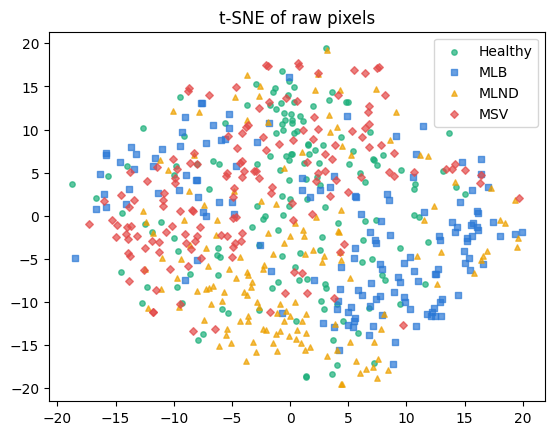

In [10]:
xy = TSNE(random_state=42).fit_transform(PCA(50).fit_transform(np.stack(eda["pixels"])))
for label in LABELS:
    keep = (eda["label"] == label).to_numpy()
    plt.scatter(*xy[keep].T, s=15, alpha=0.7, color=COLOURS[label], marker=MARKERS[label], label=label)
plt.title("t-SNE of raw pixels")
plt.legend()
plt.show()

## 3. Stage 1: the classifier

Four ImageNet backbones were trained the same way, with transfer learning: first the new head, then the top of
the backbone. Target (a): within 3 points of ResNet50 and at least 3x smaller. MobileNetV2 is chosen.

In [11]:
rows = []
for folder in sorted(MODELS.glob("clf_*")):
    info = json.loads((folder / "classifier.json").read_text())
    rows.append({"backbone": info["backbone"], "val macro-F1": info["val"]["macro_f1"],
                 "test macro-F1": info["test"]["macro_f1"],
                 "size (MB)": (folder / "classifier.onnx").stat().st_size / 1e6})
display(pd.DataFrame(rows).round(3))

,backbone,val macro-F1,test macro-F1,size (MB)
0,efficientnet_b0,0.958,0.963,16.869
1,mobilenet_v2,0.963,0.963,9.450
2,mobilenet_v3_small,0.950,0.954,4.191
3,resnet50,0.970,0.965,94.768


The chosen model's architecture, rebuilt from the code, and its training curves from `history.csv`:

In [12]:
build(classifier_info["backbone"], len(LABELS), weights=None)[0].summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 2,228,996 (8.50 MB)

 Non-trainable params: 34,112 (133.25 KB)

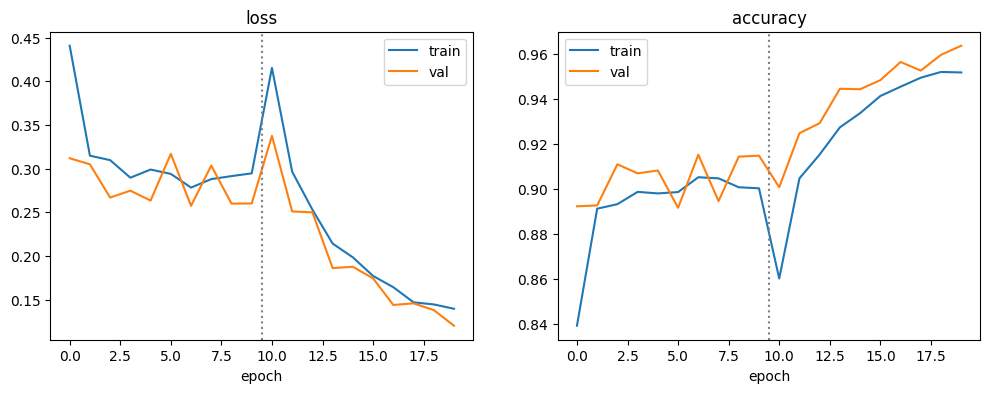

In [13]:
history = pd.read_csv(CLASSIFIER / "history.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history[metric], label="train")
    ax.plot(history["val_" + metric], label="val")
    ax.axvline((history["phase"] == "head").sum() - 0.5, color="grey", ls=":")  # fine-tuning starts here
    ax.set(title=metric, xlabel="epoch")
    ax.legend()
plt.show()

On the test photos (saved when the model was trained):

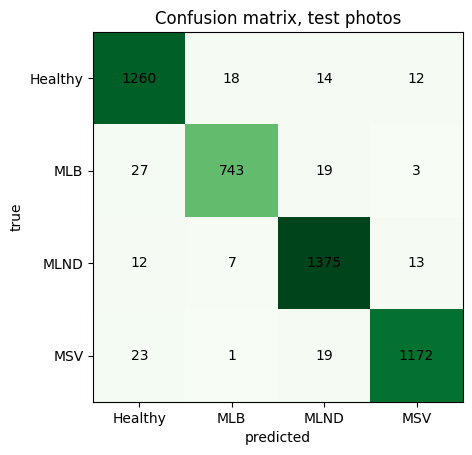

,precision,recall,f1-score
Healthy,0.953,0.966,0.960
MLB,0.966,0.938,0.952
MLND,0.964,0.977,0.970
MSV,0.977,0.965,0.971


In [14]:
matrix = np.array(classifier_info["test"]["confusion_matrix"])
plt.imshow(matrix, cmap="Greens")
plt.xticks(range(len(LABELS)), LABELS)
plt.yticks(range(len(LABELS)), LABELS)
for (true, predicted), n in np.ndenumerate(matrix):
    plt.text(predicted, true, n, ha="center", va="center")
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("Confusion matrix, test photos")
plt.show()
display(pd.DataFrame(classifier_info["test"]["per_class"]).T.loc[LABELS, ["precision", "recall", "f1-score"]].round(3))

**ROC curves and robustness.** The classifier file from Drive (the same one the web app uses) is run on 300 test
photos per class. The photos are then blurred and darkened, as farmers' photos often are, and classified again.

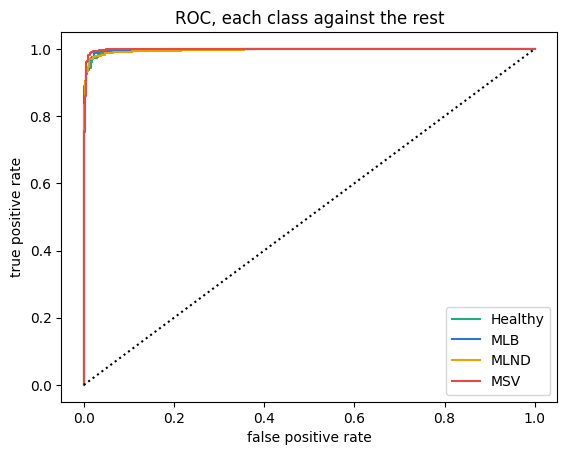

In [15]:
test = select(df, split="test")
roc_photos = test.sample(frac=1, random_state=0).groupby("label").head(300)
with ThreadPoolExecutor(16) as pool:  # resized to 224 px exactly as for training
    test_images = np.stack(list(pool.map(lambda path: resize(read_photo(path), CLS_SIZE), roc_photos["path"])))
y_true = roc_photos["label"].map(LABELS.index).to_numpy()
classify = onnx_runner(CLASSIFIER / "classifier.onnx")


def probabilities(images):
    return np.concatenate([classify(image[None].astype(np.float32)) for image in images])


probs = probabilities(test_images)
for i, label in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(y_true == i, probs[:, i])
    plt.plot(fpr, tpr, color=COLOURS[label], label=label)
plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("ROC, each class against the rest")
plt.legend()
plt.show()

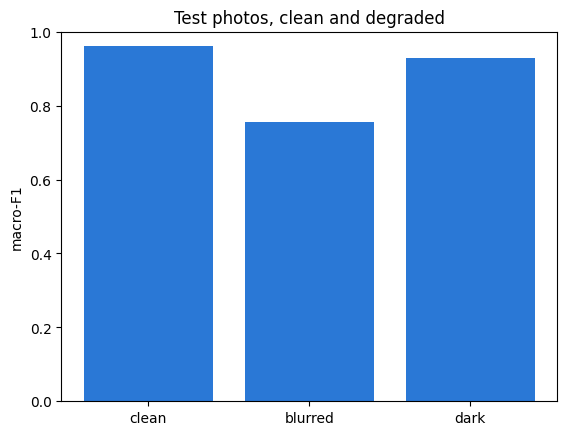

In [16]:
blurred = np.stack([cv2.GaussianBlur(image, (0, 0), 2) for image in test_images])
dark = (test_images * 0.45).astype(np.uint8)
robustness = {name: f1_score(y_true, probabilities(images).argmax(1), average="macro")
              for name, images in {"clean": test_images, "blurred": blurred, "dark": dark}.items()}
plt.bar(robustness.keys(), robustness.values(), color="#2a78d6")
plt.ylim(0, 1)
plt.ylabel("macro-F1")
plt.title("Test photos, clean and degraded")
plt.show()

## 4. The leaf mask

The autoencoder must only look at the leaf, not the soil or weeds around it. GrabCut learns the leaf's colours
from the middle of the photo (the farmer aims at the leaf) and the background's colours from the rest. Replacing
an earlier colour rule with it raised the validation AUROC from 0.65 to 0.86.

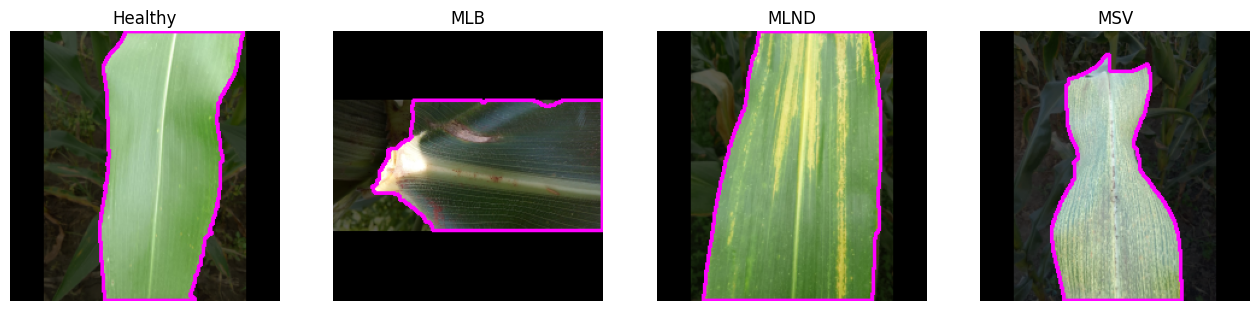

In [17]:
def outline(image, mask):
    """The photo darkened outside the leaf, with the mask edge in magenta."""
    shown = (image * 0.35).astype(np.uint8)
    shown[mask == 1] = image[mask == 1]
    edges, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return cv2.drawContours(shown, edges, -1, (255, 0, 255), 2)


examples = test.groupby("label").sample(1, random_state=1)
fig, axes = plt.subplots(1, len(examples), figsize=(16, 4))
for ax, (_, leaf) in zip(axes, examples.iterrows()):
    ax.imshow(outline(*prepare(read_photo(leaf["path"]), CLS_SIZE)))
    ax.set_title(leaf["label"])
    ax.axis("off")
plt.show()

## 5. Stage 2: the autoencoder

The autoencoder is trained on **healthy leaves only**, inside the leaf mask. A diseased leaf rebuilds badly, so
its rebuild error is the severity, and no severity labels are needed. A convolutional autoencoder and a VAE were
trained. The one that best separates healthy from diseased validation leaves (on its weakest disease) is used.

In [18]:
Autoencoder.load(AE).model.summary()

Model: "ae_conv"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Conv2D)                   │ (None, 8, 8, 32)       │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 256)    │        73,984 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ recon (Conv2D)                  │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 858,787 (3.28 MB)

 Trainable params: 858,787 (3.28 MB)

 Non-trainable params: 0 (0.00 B)

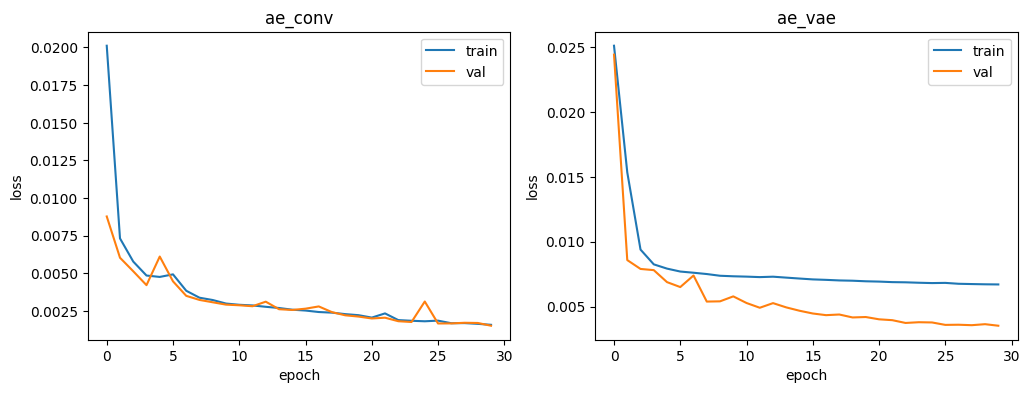

,kind,error,worst_auroc,mean_auroc
0,conv,plain,0.843,0.858
1,vae,plain,0.816,0.851
2,vae,smoothed,0.799,0.858
3,conv,smoothed,0.716,0.843


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, folder in zip(axes, sorted(RUN.glob("ae_*"))):
    history = pd.read_csv(folder / "history.csv")
    ax.plot(history["loss"], label="train")
    ax.plot(history["val_loss"], label="val")
    ax.set(title=folder.name, xlabel="epoch", ylabel="loss")
    ax.legend()
plt.show()

display(compare(RUN)[["kind", "error", "worst_auroc", "mean_auroc"]].round(3))  # on validation; the top row is used

## 6. Test results against the targets

The test photos were used once, after every choice was made on validation.

* **(b)** AUROC (healthy vs each disease) >= 0.80
* **(c)** Spearman with the symptomatic area A(x) >= 0.40 for MLND and MLB, and better than both baselines.
  A(x) is the % of the leaf in a symptom colour (yellowing, brown lesions, dead tissue).

In [20]:
results = pd.DataFrame({
    disease: {"AUROC": r["auroc_vs_healthy"], "Spearman vs A(x)": r["spearman_vs_area"],
              **{f"baseline: {name}": value for name, value in metrics["baselines"][disease].items()}}
    for disease, r in metrics["diseases"].items()}).T
results["(b) met"] = results["AUROC"] >= 0.80
results["(c) met"] = results["Spearman vs A(x)"] >= 0.40
display(results.round(3))

,AUROC,Spearman vs A(x),baseline: colour_distance,baseline: classifier_1_minus_p_healthy,(b) met,(c) met
MLB,0.862,0.312,0.157,0.220,True,False
MLND,0.843,0.345,0.430,0.383,True,False
MSV,0.862,0.273,0.180,0.284,True,False


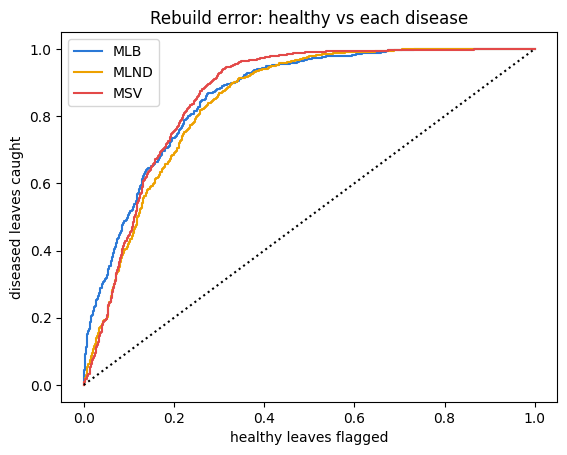

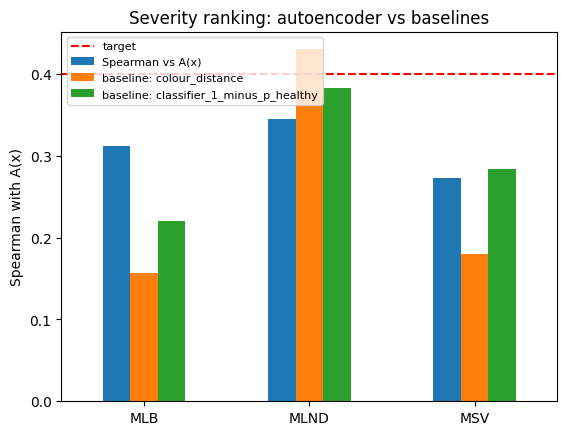

In [21]:
scores = pd.read_csv(AE / "test_scores.csv")
healthy = scores.loc[scores["label"] == HEALTHY, "error"]
for disease, part in scores[scores["label"] != HEALTHY].groupby("label"):
    is_disease = np.r_[np.zeros(len(healthy)), np.ones(len(part))]
    fpr, tpr, _ = roc_curve(is_disease, np.r_[healthy, part["error"]])
    plt.plot(fpr, tpr, color=COLOURS[disease], label=disease)
plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("healthy leaves flagged")
plt.ylabel("diseased leaves caught")
plt.title("Rebuild error: healthy vs each disease")
plt.legend()
plt.show()

results.filter(like="Spearman").join(results.filter(like="baseline")).plot.bar(rot=0)
plt.axhline(0.40, color="red", ls="--", label="target")
plt.ylabel("Spearman with A(x)")
plt.title("Severity ranking: autoencoder vs baselines")
plt.legend(fontsize=8)
plt.show()

Saved by `maize-evaluate`: the rebuild error per class, and where on the leaf the error sits.

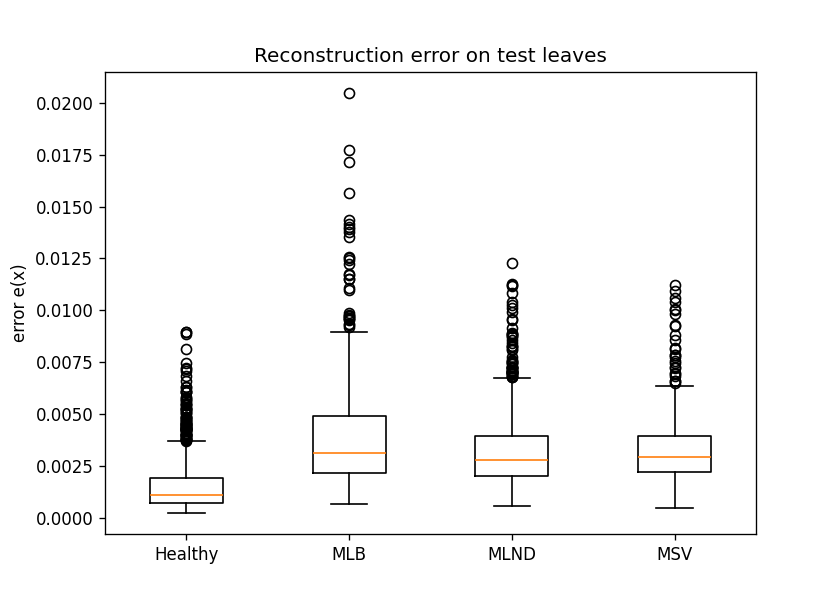

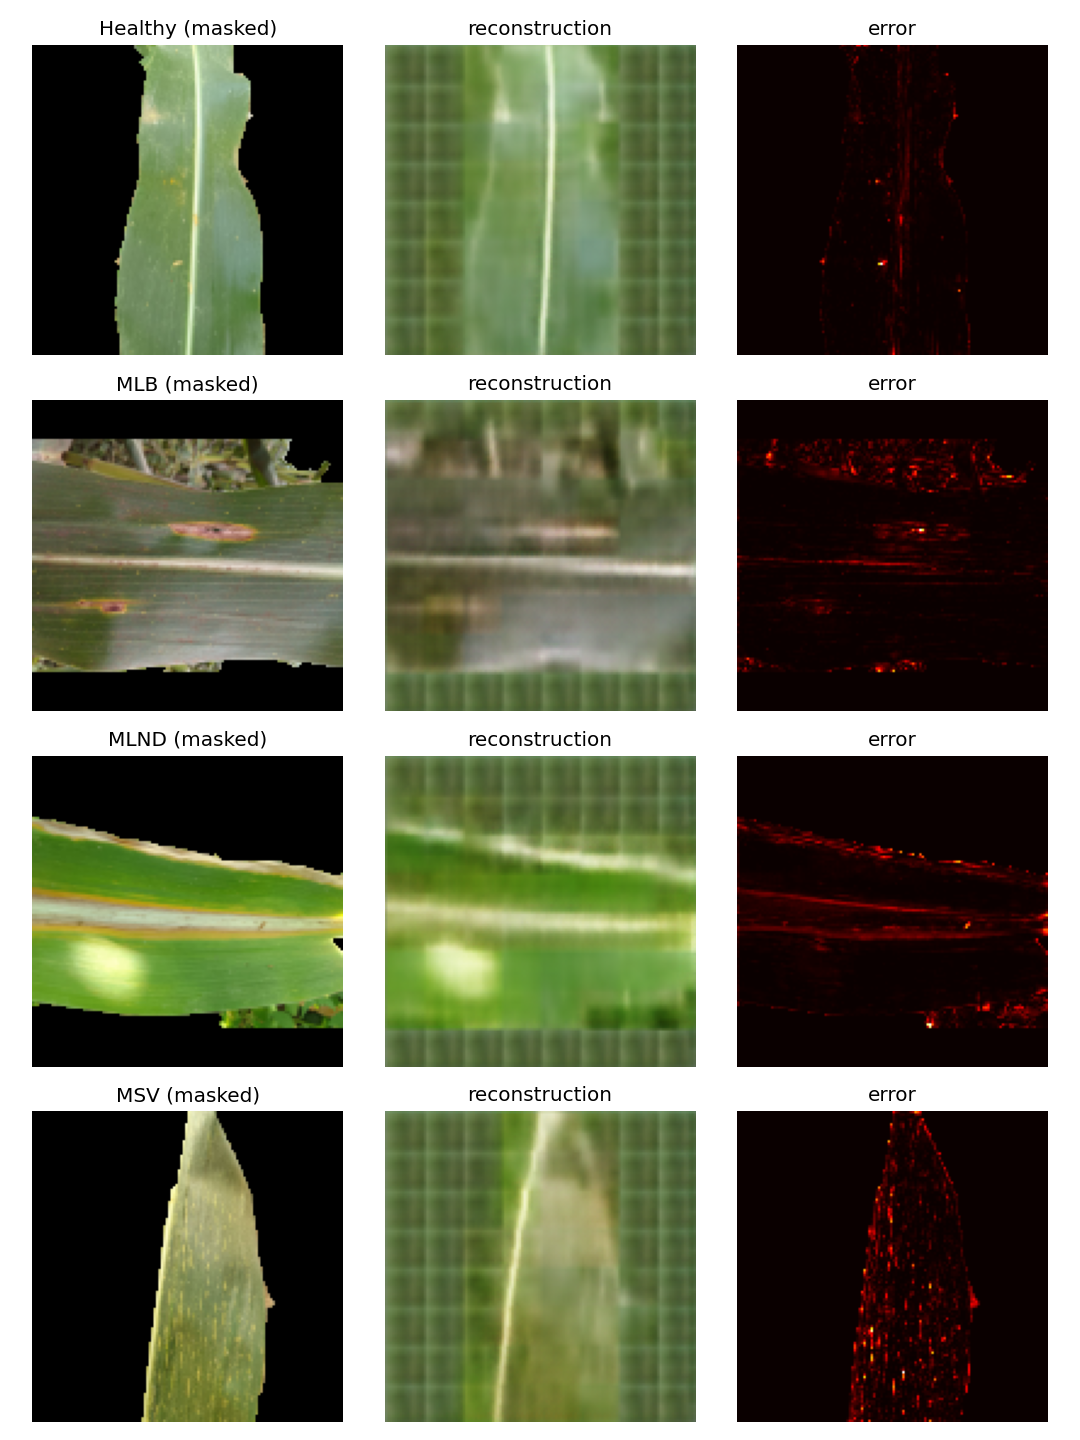

In [22]:
display(Image(str(AE / "error_by_class.png")))
display(Image(str(AE / "heatmaps.png")))

## 7. The full pipeline

Exactly what the web app does with a photo (`maize.serve.Scorer`):

1. the classifier names the disease (below 60% confidence the app asks for a new photo);
2. the leaf mask is found and the autoencoder rebuilds the leaf;
3. the rebuild error becomes a 0-1 severity score: mild below 0.35, moderate below 0.70, otherwise severe.

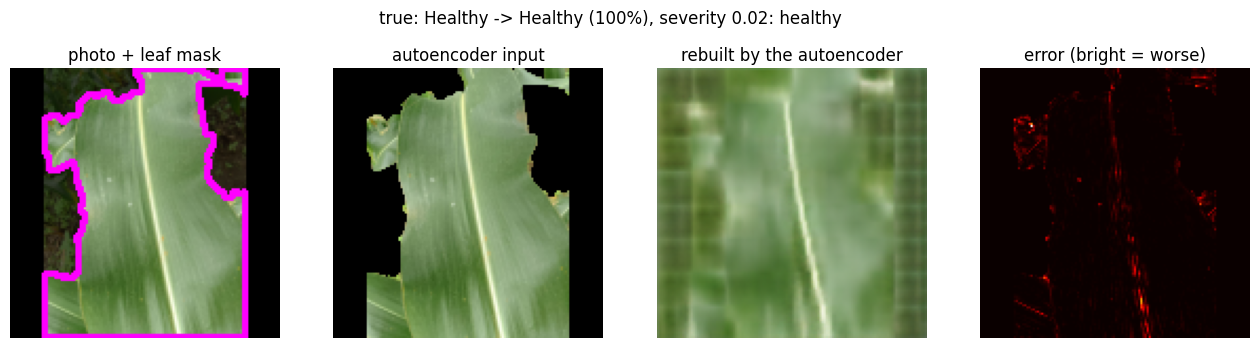

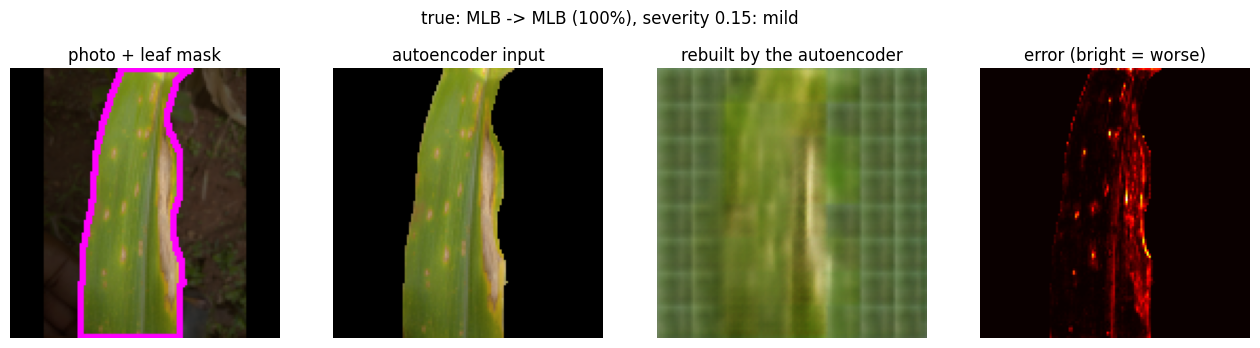

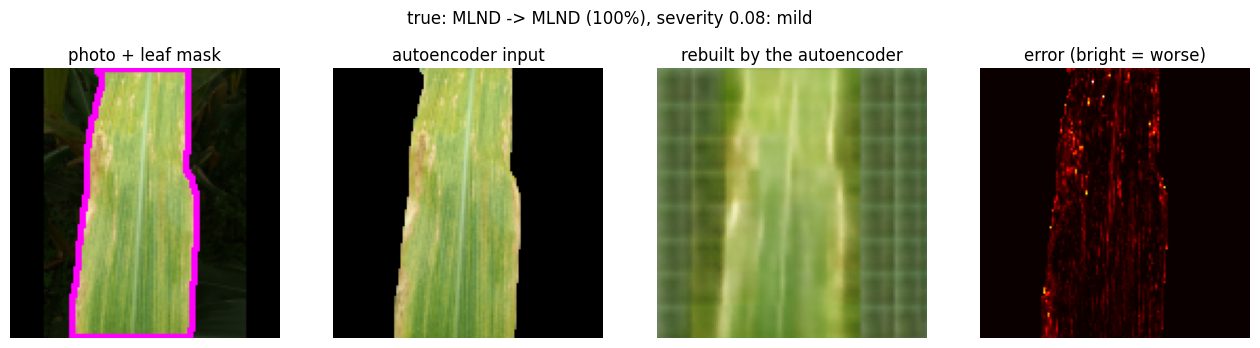

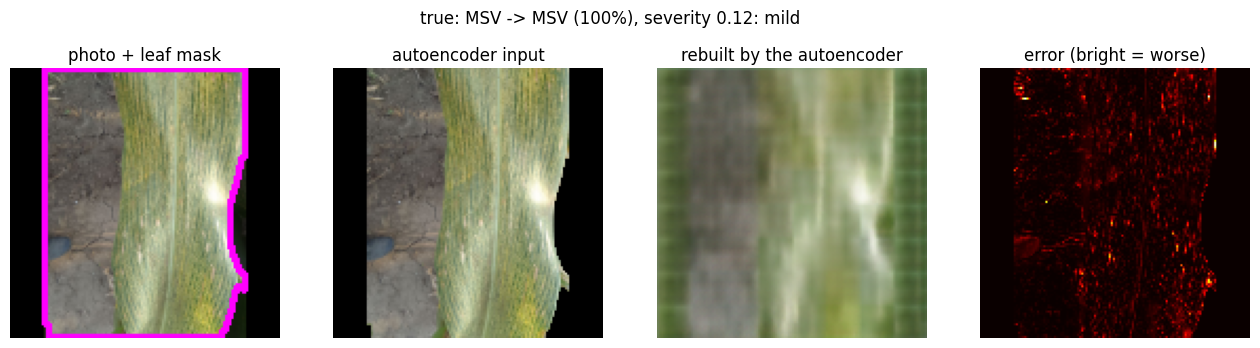

In [23]:
scorer = Scorer(classify, onnx_runner(AE / "model.onnx"), classifier_info, calibration)


def grade(label, score):
    if label == HEALTHY:
        return "healthy"
    return "mild" if score < 0.35 else "moderate" if score < 0.70 else "severe"


def show(photo, title):
    result = scorer.score(photo)
    image, mask = prepare(photo, AE_SIZE)
    masked = mask_background(image[None], mask[None])
    rebuilt = scorer.reconstruct(masked.astype(np.float32))
    error = error_map(image[None], rebuilt, mask[None], calibration.get("smooth_sigma", 0))[0]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    steps = {"photo + leaf mask": outline(image, mask), "autoencoder input": masked[0],
             "rebuilt by the autoencoder": rebuilt[0], "error (bright = worse)": error}
    for ax, (name, picture) in zip(axes, steps.items()):
        ax.imshow(picture, cmap="hot")
        ax.set_title(name)
        ax.axis("off")
    fig.suptitle(f"{title} -> {result['label']} ({result['confidence']:.0%}), "
                 f"severity {result['score']:.2f}: {grade(result['label'], result['score'])}")
    plt.show()


for _, leaf in test.groupby("label").sample(1, random_state=7).iterrows():
    show(read_photo(leaf["path"]), f"true: {leaf['label']}")

## Limitations

* Detection (b) is met for every disease. Severity ranking (c) is not met: Spearman with A(x) is 0.27-0.34, below
  0.40. It beats both baselines only for MLB; for MLND the simple colour distance ranks severity better, because
  broad yellowing is partly rebuilt by the autoencoder.
* A(x) is a colour rule, not an expert's rating, so it is a reference, not ground truth.
* Some photos in the Healthy folder are not maize (e.g. bean leaves).
* The robustness check uses synthetic blur and darkening, not real poor-quality field photos.